In [1]:
import polars as pl
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
counters = pl.read_csv("../../data/counters.csv", try_parse_dates=True)
counters.head()

,counter_site_id,counter_serial,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation,datetime
i64,i64,str,f64,f64,str,i64,f64,f64,"datetime[μs, UTC]"
0,100003358,"""YTH24052174""",4.0,1.0,null,5,0.0,0.0,2020-12-31 23:00:00 UTC
1,100003358,"""YTH24052174""",2.0,0.0,null,2,0.0,0.0,2021-01-01 00:00:00 UTC
2,100003358,"""YTH24052174""",1.0,0.0,null,1,0.0,0.0,2021-01-01 01:00:00 UTC
3,100003358,"""YTH24052174""",2.0,0.0,null,2,0.0,0.0,2021-01-01 02:00:00 UTC
4,100003358,"""YTH24052174""",0.0,0.0,null,0,0.0,0.0,2021-01-01 03:00:00 UTC


In [3]:
gaps_in_counters = (
    counters.group_by(
        pl.col("datetime").dt.date(),
        pl.col("counter_site_id"),
    )
    .agg(pl.col("channels_all").max())
    .filter(pl.col("channels_all") == 0)
    .group_by(pl.col("counter_site_id")).len()
)

<Axes: ylabel='Probability'>

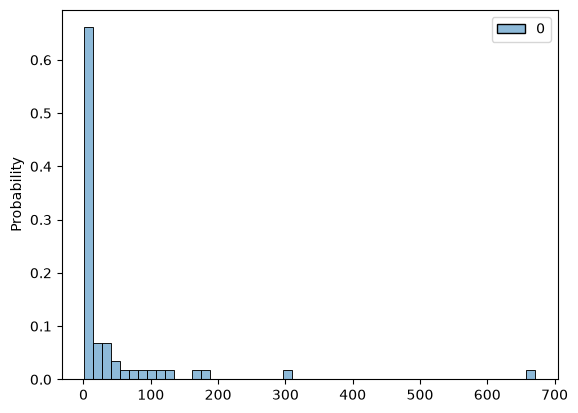

In [4]:
sns.histplot(gaps_in_counters.select(pl.col("len")), stat="probability", bins=50)

In [18]:
q = (
    gaps_in_counters
    .select(pl.col("len").quantile(0.95))
).item()
counters_with_gaps = (
    gaps_in_counters
    .filter(pl.col("len") > q)
)
counters_with_gaps

counter_site_id,len
i64,u32
100048814,671
100056853,307
100017862,181


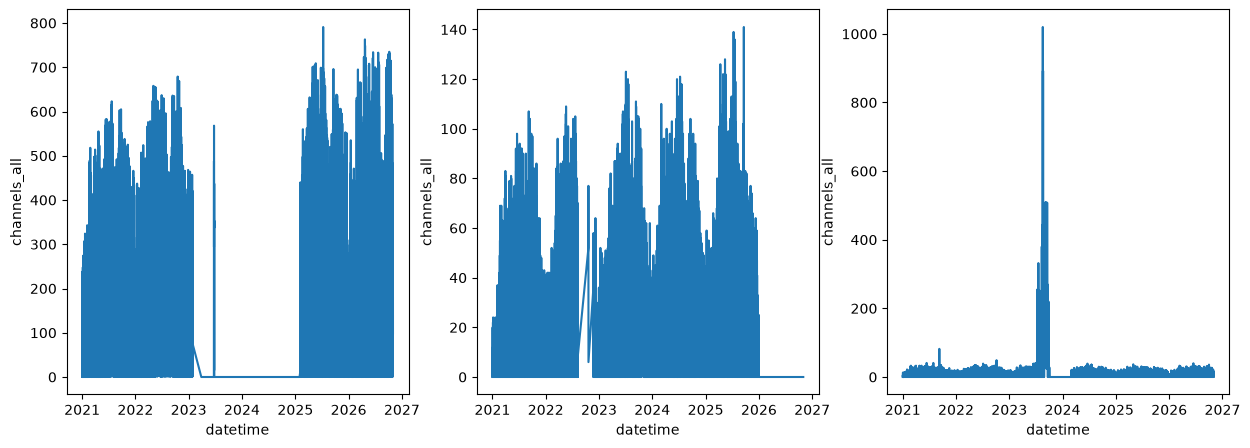

In [19]:
N = counters_with_gaps.shape[0]
fig, axs = plt.subplots(1, N, figsize=(5*N, 5))

for i in range(N):
    ax = axs[i]
    site_id, l = counters_with_gaps.row(i)
    station = counters.filter(pl.col("counter_site_id") == site_id)
    sns.lineplot(data=station.to_pandas(), x="datetime", y="channels_all", ax=ax)

# Clearly some counters have significant gaps, and also outliers in the upper direction which are probably measuring errors

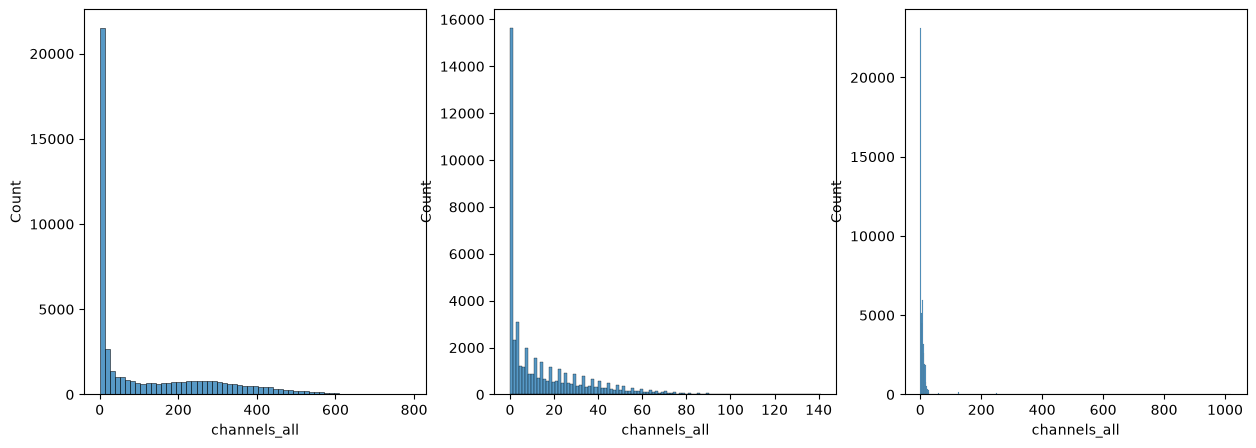

In [20]:
N = counters_with_gaps.shape[0]
fig, axs = plt.subplots(1, N, figsize=(5*N, 5))

for i in range(N):
    ax = axs[i]
    site_id, l = counters_with_gaps.row(i)
    station = counters.filter(pl.col("counter_site_id") == site_id)
    sns.histplot(data=station.to_pandas(), x="channels_all", ax=ax)

# Clearly some counters have significant gaps, and also outliers in the upper direction which are probably measuring errors

<Axes: >

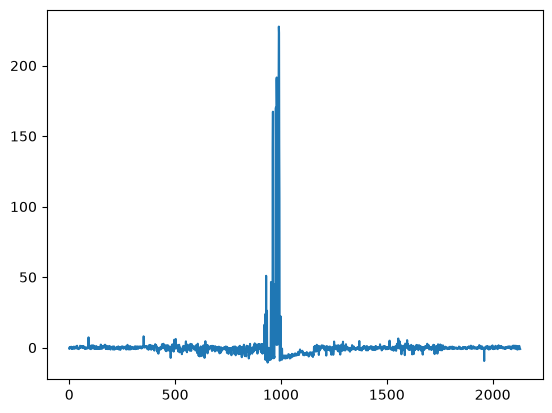

In [44]:
from statsmodels.tsa.seasonal import STL
from statsmodels.robust.scale import mad

worst_station = counters.filter(pl.col("counter_site_id") == 100017862).group_by(pl.col("datetime").dt.date()).agg(pl.col("channels_all").mean()).sort(pl.col("datetime"))
y = worst_station.select(pl.col("channels_all")).to_numpy()

fit_stl = STL(y, period=365, robust=True).fit()
residual = fit_stl.resid
center = np.median(residual)
score = np.abs(residual - center)/mad(residual)
sns.lineplot(residual)
